In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
import seaborn as sns

In [5]:
df = pd.read_csv("cleaned_transactions.csv")

In [6]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

In [7]:
fraud_by_type = df.groupby("transaction_type")["is_fraud"].mean() * 100

# sort it so the highest fraud rate shows first
fraud_by_type = fraud_by_type.sort_values(ascending=False)

print(fraud_by_type)

transaction_type
RTGS              1.853537
Cheque            1.179126
NEFT              0.872176
Credit_Card       0.852307
Net_Banking       0.847678
ATM_Withdrawal    0.827496
IMPS              0.809990
POS               0.797969
UPI               0.786435
Auto_Debit        0.682034
Name: is_fraud, dtype: float64


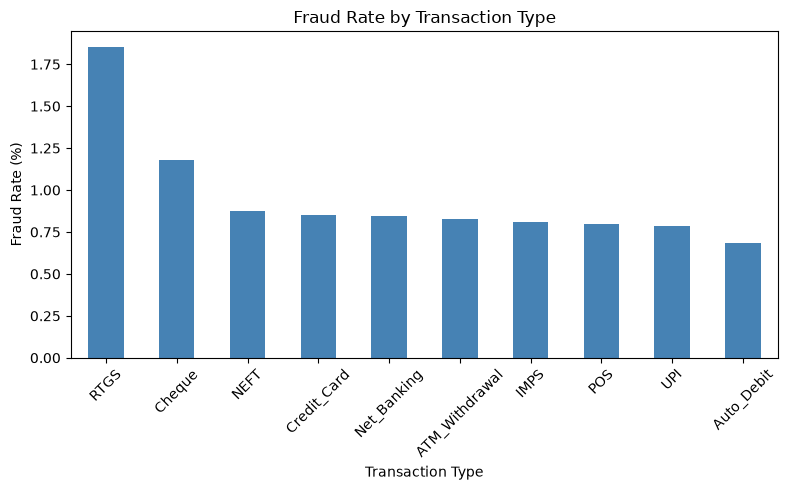

In [8]:
plt.figure(figsize=(8, 5))  # chart size in inches (width, height)

fraud_by_type.plot(kind="bar", color="steelblue")

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)  # tilts the x-axis labels so they don't overlap
plt.tight_layout()       # prevents labels from getting cut off at the edges

plt.savefig("fraud_rate_by_transaction_type.png", dpi=200)  # saves the chart as an image file, for your README
plt.show()  # actually displays it in the notebook

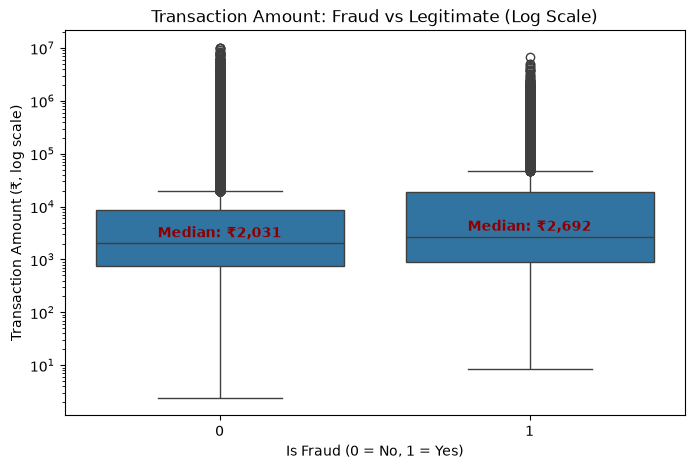

In [11]:
plt.figure(figsize=(8, 5))

ax = sns.boxplot(data=df, x="is_fraud", y="transaction_amount")
plt.yscale("log")

# calculate the actual median for each group, so we can print it as text
medians = df.groupby("is_fraud")["transaction_amount"].median()

# loop through each box (0 and 1) and place a text label above its median line
for i, val in enumerate(medians):
    ax.text(i, val * 1.3, f"Median: ₹{val:,.0f}", 
            ha="center", fontsize=10, fontweight="bold", color="darkred")

plt.title("Transaction Amount: Fraud vs Legitimate (Log Scale)")
plt.xlabel("Is Fraud (0 = No, 1 = Yes)")
plt.ylabel("Transaction Amount (₹, log scale)")

plt.savefig("amount_distribution_by_fraud_log.png", dpi=200)
plt.show()